In [2]:
import tensorflow as tf
import matplotlib.pyplot as plt
#load the dataset mnist
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


(28, 28)


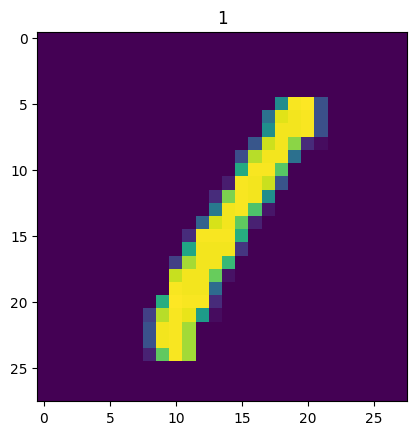

(60000, 28, 28)
(10000, 28, 28)


In [3]:
#visulize the data
class_name=["0","1","2","3","4","5","6","7","8","9"]
index  =3
plt.imshow(X_train[index])
print(X_train[0].shape)
plt.title(class_name[y_train[index]])
plt.show()
len(X_train) , len(y_test)
print(X_train.shape)
print(X_test.shape)

In [4]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
IMAGE_SHAPE=(224,224)
BATCH_SIZE = 32

def preprocess(image, label):
    image = tf.expand_dims(image, -1)              # add extra dimension for color(28,28,1)
    image = tf.image.grayscale_to_rgb(image)       # color(28,28,3)
    image = tf.image.resize(image, IMAGE_SHAPE)    # rescale the img(224,224,3)
    image = tf.cast(image, tf.float32)
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image) #0-1
    return image, label
# AUTOTUNE == speedup CPUCORS
train_data = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)#==>process all images use Cpu_Core
    #autoTune : cpu workers are best for the computer
    #PREPROCESS IMAGE
    # groups them into batches
    #PREPARE NEXT BACTH WHILE THE CURRENT IS ON TRAINING
    .batch(BATCH_SIZE) ## group the 32 image
    .prefetch(tf.data.AUTOTUNE) #use cpu to prepare next batch, keep the gpu busy
)
# train_data[0]

test_data = (
    tf.data.Dataset.from_tensor_slices((X_test, y_test))
    .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)#==>
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)
print(type(train_data))
# <class 'tensorflow.python.data.ops.prefetch_op._PrefetchDataset'>


##return a "DATASET OBJECT"
#flow_form_directory return a "DirectoryIterator"
# <class 'keras.src.legacy.preprocessing.image.DirectoryIterator'>


<class 'tensorflow.python.data.ops.prefetch_op._PrefetchDataset'>


##does not create data itself , It create or loads tensors whenever the model ask for next batch

###model.fit"Give me the next batch of image tensors and label tensors."

In [ ]:
from tensorflow.keras.layers import Dense,Conv2D,MaxPooling2D, Activation,Flatten
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import  optimizers, losses, metrics
from tensorflow.keras import layers
IMAGE_SHAPE = (224, 224)

#CORE
def create_model(backbone, num_class):
  feature_extractor = backbone(
      weights="imagenet", #1.2m img
      include_top=False, ## mobilenet -->feature extractor only
      # instead of 1000 output imagnetclass "cat dog mouse"  --> (0-9)
# Image
# ↓
# Many convolution layers
# ↓
# 1000-class classifier (true) !!!! (0-9) "false"
      input_shape=IMAGE_SHAPE+(3,), ##rgb
      pooling="avg"
  )

  feature_extractor.trainable =False #Do not update them
  #   edges
  # corners
  # curves
  # textures
  # shapes
  #Don't change MobileNet's learned weights. dont erase that knowledge
  # Only the last layer will learn.
  model= tf.keras.Sequential([
      feature_extractor,
      Dense(num_class,activation="softmax",name="output_layer")
  ])
  return model
mobilenet_model = create_model(MobileNetV2, 10)
mobilenet_model.compile(loss="sparse_categorical_crossentropy",
                     optimizer= tf.keras.optimizers.Adam(),
                     metrics=["accuracy"])

In [ ]:
mobilenet_model.summary()

In [ ]:
history =  mobilenet_model.fit(train_data,epochs=5,validation_data=test_data)

In [ ]:
images, labels = next(iter(train_data))

print(images.shape)
print(labels.shape)
print(X_train.shape)
print(X_test.shape)

In [ ]:
mobilenet_model.evaluate(test_data)

In [ ]:
from PIL import Image
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess_input

IMAGE_SHAPE = (224, 224) #==>28,28

img = Image.open("8.png")
img = img.convert("L")#Convert to grayscale. 1 channel
img = img.resize((28, 28))
img = np.array(img)

# Convert to TensorFlow tensor and apply preprocessing steps
img_tensor = tf.convert_to_tensor(img, dtype=tf.float32) # (28, 28)
img_tensor = tf.expand_dims(img_tensor, -1)              # (28, 28, 1)
img_tensor = tf.image.grayscale_to_rgb(img_tensor)       # (28, 28, 3)
img_tensor = tf.image.resize(img_tensor, IMAGE_SHAPE)    # (224, 224, 3)
img_tensor = mobilenet_preprocess_input(img_tensor)      # (224, 224, 3) Normalize to [-1, 1]
img_tensor = tf.expand_dims(img_tensor, axis=0)          # (1, 224, 224, 3) Add batch dimension

prediction = mobilenet_model.predict(img_tensor)
digit = np.argmax(prediction)
confidence = np.max(prediction)

print(f"Predicted digit: {digit} with confidence: {confidence:.4f}")

In [ ]:
import pandas as pd
def plot_histort(history):
  df = pd.DataFrame(history.history)
  epoch = range(len(df["loss"]))
  fig ,(ax1, ax2) = plt.subplots(1,2,figsize=(12,7))
  ax1.plot(epoch, df['accuracy'], label="train_accuracy")
  ax1.plot(epoch, df['val_accuracy'], label="val_accuracy")
  ax1.set_xlabel("epoch")
  ax1.set_ylabel("accuracy")
  ax1.set_title("accuracy")
  ax1.legend()
  ax2.plot(epoch, df['loss'], label="train_loss")
  ax2.plot(epoch, df['val_loss'], label="val_loss")
  ax2.set_xlabel("epoch")
  ax2.set_ylabel("loss")
  ax2.set_title("Loss")
  ax2.legend()
  plt.tight_layout()
  plt.show()
plot_histort(history)

In [ ]:
mobilenet_model.save('my_model.keras')
